# Can a screenplay's vocabulary tell you its genre?

**Question:** Using only how often words appear in a movie's script, how accurately can we tell a **comedy** from a **thriller**, and what does the model actually learn?

**Data:** 333 movie screenplays (119 comedies, 214 thrillers). Each row holds the proportion of the script made up by each of ~5,000 stemmed words (`kill`, `happi`, `cop`, ...), so each row sums to 1.

**What this notebook does**
1. Sets an honest baseline.
2. Rebuilds a k-nearest-neighbors classifier on 10 hand-picked words, and picks *k* with cross-validation instead of guessing.
3. Shows why throwing all 5,000 words at k-NN makes it *worse*, and how feature selection fixes it.
4. Trains a regularized logistic regression on log-scaled word frequencies, which turns out best.
5. Opens up the model: which words push toward each genre, and which movies fool it.

Every accuracy below is **5-fold stratified cross-validation, repeated 5 times** (25 fits), unless stated otherwise. Any feature selection happens *inside* each fold, so no information leaks from the test folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, cross_val_predict, GridSearchCV)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
COMEDY, THRILLER = "#E8A33D", "#3A6EA5"
SEED = 0

## 1. Load and look at the data

In [2]:
movies = pd.read_csv("data/movies.csv")
meta_cols = ["Title", "Year", "Rating", "Genre", "# Words"]
X = movies.drop(columns=meta_cols)          # word proportions
y = (movies["Genre"] == "thriller").astype(int)   # 1 = thriller, 0 = comedy

print(f"{len(movies)} movies, {X.shape[1]:,} word features")
print(movies["Genre"].value_counts().to_string())
print("Every row sums to 1:", np.allclose(X.sum(axis=1), 1))
movies[meta_cols + ["kill", "love", "cop", "happi"]].head()

333 movies, 5,000 word features
Genre
thriller    214
comedy      119
Every row sums to 1: True


,Title,Year,Rating,Genre,# Words,kill,love,cop,happi
0,10 things i hate about you,1999,6.9,comedy,5341,0.000398,0.000597,0.000000,0.000000
1,sister act,1992,5.9,comedy,7401,0.000704,0.002534,0.000422,0.000422
2,the boondock saints,1999,7.8,thriller,5705,0.004118,0.000936,0.000374,0.000187
3,mystery men,1999,5.9,comedy,3144,0.002316,0.001654,0.000000,0.000000
4,blade,1998,7.0,thriller,2886,0.002196,0.000000,0.000000,0.000366


The classes are imbalanced: about **64% of the movies are thrillers**. A model that always says "thriller" is already 64% accurate, so that's the number to beat.

In [3]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

def evaluate(model, features=X):
    scores = cross_val_score(model, features, y, cv=cv, n_jobs=-1)
    return scores.mean(), scores.std()

results = {}
results["Always guess thriller"] = evaluate(DummyClassifier(strategy="most_frequent"))
print("Baseline accuracy: %.3f" % results["Always guess thriller"][0])

Baseline accuracy: 0.643


## 2. k-NN on 10 hand-picked words

The starting point: pick words that *feel* genre-specific (violence and police for thrillers, relationships and fun for comedies), then classify a movie by majority vote among its *k* most similar movies.

Instead of hard-coding *k*, try a range and let cross-validation choose.

Best k = 23: accuracy 0.796


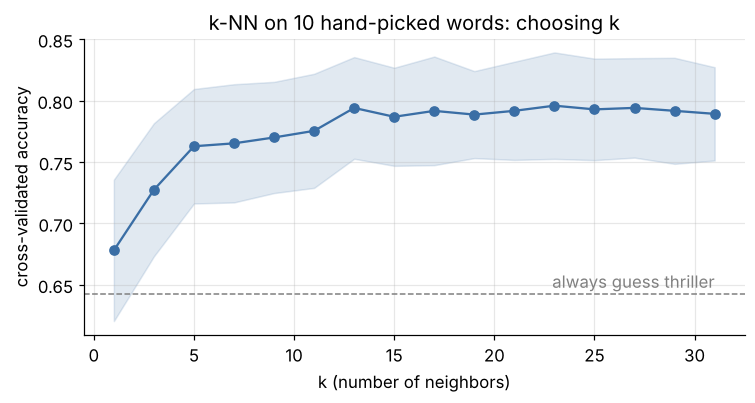

In [4]:
hand_picked = ["murder", "cop", "dead", "kill", "gun",          # thriller-ish
               "love", "marri", "happi", "friend", "fun"]       # comedy-ish

ks = list(range(1, 32, 2))
k_curve = [evaluate(KNeighborsClassifier(k), X[hand_picked]) for k in ks]
k_means = np.array([m for m, s in k_curve]); k_stds = np.array([s for m, s in k_curve])
best_k = ks[int(np.argmax(k_means))]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ks, k_means, marker="o", color=THRILLER)
ax.fill_between(ks, k_means - k_stds, k_means + k_stds, color=THRILLER, alpha=0.15)
ax.axhline(results["Always guess thriller"][0], ls="--", color="gray", lw=1)
ax.text(ks[-1], results["Always guess thriller"][0] + 0.005, "always guess thriller", ha="right", color="gray")
ax.set(xlabel="k (number of neighbors)", ylabel="cross-validated accuracy",
       title="k-NN on 10 hand-picked words: choosing k")
plt.tight_layout(); plt.savefig("figures/knn_choose_k.png", bbox_inches="tight"); plt.show()

results[f"k-NN, 10 hand-picked words (k={best_k})"] = evaluate(KNeighborsClassifier(best_k), X[hand_picked])
print(f"Best k = {best_k}: accuracy {k_means.max():.3f}")

Ten hand-picked words already beat the baseline by a wide margin. Very small *k* is noisy (one odd neighbor can flip the vote), and accuracy levels off once *k* reaches the mid-teens.

## 3. More words should help... right?

The obvious next step is to give k-NN *all* ~5,000 words. It gets **worse**:

In [5]:
for k in [best_k]:
    results[f"k-NN, all 5,000 words (k={k})"] = evaluate(KNeighborsClassifier(k))
    print("all words:   %.3f" % results[f"k-NN, all 5,000 words (k={k})"][0])

all words:   0.753


This is the **curse of dimensionality**. Euclidean distance over 5,000 dimensions is dominated by thousands of words that have nothing to do with genre, plus the handful of very common words (`the`, `you`) with the biggest raw proportions. Movies stop looking meaningfully "near" each other.

The fix is to let the data choose the words. A chi-squared test ranks each word by how unevenly it's spread across genres. Fitted inside every training fold, it keeps the test folds honest:

In [6]:
n_words = [5, 10, 20, 50, 100, 200, 400]
sel_curve = []
for n in n_words:
    pipe = make_pipeline(SelectKBest(chi2, k=n), StandardScaler(), KNeighborsClassifier(best_k))
    sel_curve.append(evaluate(pipe))
sel_means = np.array([m for m, s in sel_curve])
best_n = n_words[int(np.argmax(sel_means))]
results[f"k-NN, top {best_n} words by chi² (k={best_k})"] = sel_curve[int(np.argmax(sel_means))]
pd.DataFrame({"words kept": n_words, "accuracy": sel_means.round(3)})

,words kept,accuracy
0,5,0.773
1,10,0.798
2,20,0.780
3,50,0.786
4,100,0.765
5,200,0.660
6,400,0.643


Choosing the vocabulary automatically matches or beats hand-picking at its best, but k-NN starts falling apart again as more words come in. k-NN gives every feature an equal vote in the distance, so it can't learn that `kill` matters more than `door`.

## 4. Logistic regression: let the model weight the words

Logistic regression learns a weight for every word, and L2 regularization keeps those weights small so it doesn't overfit 333 movies with 5,000 features. One more trick: word frequencies are heavily skewed (a few scripts say "kill" 50× more than average), so a **log transform** first stops a handful of extreme scripts from dominating.

In [7]:
log_scale = FunctionTransformer(lambda a: np.log1p(1000 * np.asarray(a)))

first_logreg = make_pipeline(log_scale, StandardScaler(), LogisticRegression(C=0.1, max_iter=5000))
results["Logistic regression, log-scaled"] = evaluate(first_logreg)
print("accuracy: %.3f" % results["Logistic regression, log-scaled"][0])

first_logreg.fit(X, y)
first_coefs = pd.Series(first_logreg[-1].coef_[0], index=X.columns)
used_in = (X > 0).sum()
print("\nStrongest 'comedy' words and how many of the 333 scripts use them:")
first_coefs.nsmallest(10).to_frame("weight").assign(scripts_using_word=used_in).round(3)

accuracy: 0.852

Strongest 'comedy' words and how many of the 333 scripts use them:


,weight,scripts_using_word
oh,-0.073,318
well,-0.053,329
nice,-0.053,260
excit,-0.052,101
gruner,-0.050,1
uh,-0.050,173
love,-0.049,278
ooh,-0.048,19
hei,-0.047,254
bastaldi,-0.047,1


That's already the best so far, but the weights reveal a problem. Two of the ten strongest "comedy" words, `gruner` and `bastaldi`, are **character names that each appear in exactly one script**. The model is partly memorizing specific movies instead of learning genre vocabulary. Names won't generalize to new movies.

Two fixes:
- **Drop rare words.** Ignore any word used in fewer than a minimum share of the training scripts. It's a hyperparameter, so it gets tuned.
- **Balance the classes.** With 64% thrillers, the model leans toward "thriller", so give comedy examples proportionally more weight.

Both settings and the regularization strength `C` are chosen by an inner cross-validation loop (**nested CV**), so the reported accuracy is never computed on data that helped pick them.

In [8]:
from sklearn.base import BaseEstimator, TransformerMixin

class MinDocFrequency(BaseEstimator, TransformerMixin):
    # Keep only words that appear in at least `min_share` of the training scripts.
    def __init__(self, min_share=0.0):
        self.min_share = min_share
    def fit(self, X, y=None):
        self.keep_ = (np.asarray(X) > 0).mean(axis=0) >= self.min_share
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.keep_]

final_pipeline = make_pipeline(MinDocFrequency(), log_scale, StandardScaler(),
                               LogisticRegression(class_weight="balanced", max_iter=5000))
grid = {"mindocfrequency__min_share": [0.0, 0.03, 0.06, 0.10, 0.15],
        "logisticregression__C": [0.01, 0.1, 1]}
inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
tuned_logreg = GridSearchCV(final_pipeline, grid, cv=inner, n_jobs=-1)

results["Logistic regression, log-scaled + rare words dropped (tuned)"] = evaluate(tuned_logreg)

# Naive Bayes on raw word counts: the classic text-classification baseline
counts = X.mul(movies["# Words"], axis=0).round()
results["Naive Bayes, word counts"] = evaluate(MultinomialNB(), counts)

for name in ["Logistic regression, log-scaled + rare words dropped (tuned)", "Naive Bayes, word counts"]:
    print(f"{name:62s} {results[name][0]:.3f}")

Logistic regression, log-scaled + rare words dropped (tuned)   0.877
Naive Bayes, word counts                                       0.865


## 5. Comparing every approach

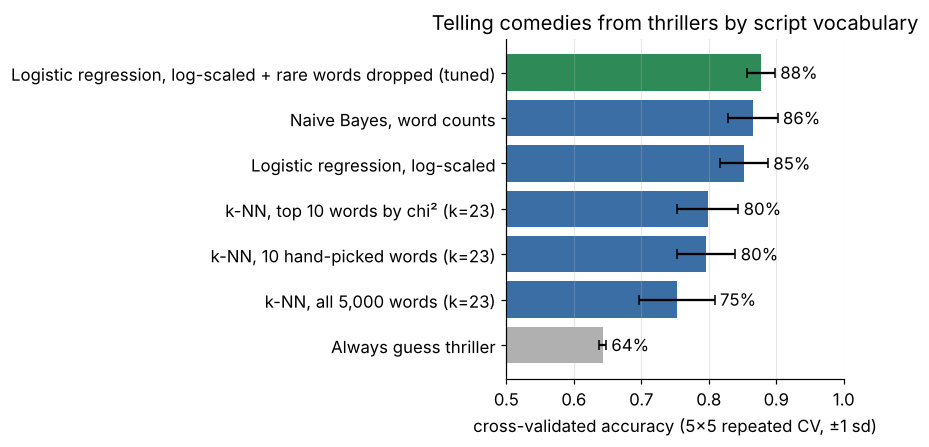

,accuracy,std
Always guess thriller,0.643,0.005
"k-NN, all 5,000 words (k=23)",0.753,0.056
"k-NN, 10 hand-picked words (k=23)",0.796,0.043
"k-NN, top 10 words by chi² (k=23)",0.798,0.045
"Logistic regression, log-scaled",0.852,0.035
"Naive Bayes, word counts",0.865,0.037
"Logistic regression, log-scaled + rare words dropped (tuned)",0.877,0.021


In [9]:
summary = (pd.DataFrame(results, index=["accuracy", "std"]).T
           .sort_values("accuracy"))
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = ["#B0B0B0" if "guess" in n else ("#2E8B57" if "tuned" in n and "Logistic" in n else THRILLER) for n in summary.index]
ax.barh(summary.index, summary["accuracy"], xerr=summary["std"], color=colors, capsize=3)
for i, v in enumerate(summary["accuracy"]):
    ax.text(v + summary["std"].iloc[i] + 0.008, i, f"{v:.0%}", va="center")
ax.set_xlim(0.5, 1.0); ax.grid(axis="y", visible=False)
ax.set(xlabel="cross-validated accuracy (5×5 repeated CV, ±1 sd)",
       title="Telling comedies from thrillers by script vocabulary")
plt.tight_layout(); plt.savefig("figures/model_comparison.png", bbox_inches="tight"); plt.show()
summary.round(3)

## 6. What did the model learn?

Fit the tuned logistic regression on all the data and read off its weights. Positive weights push toward **thriller**, negative ones toward **comedy**. (The words are *stems*, so `happi` covers happy, happiness, happily.)

Chosen settings: {'logisticregression__C': 0.01, 'mindocfrequency__min_share': 0.1}
Words kept: 1,848 of 5,000


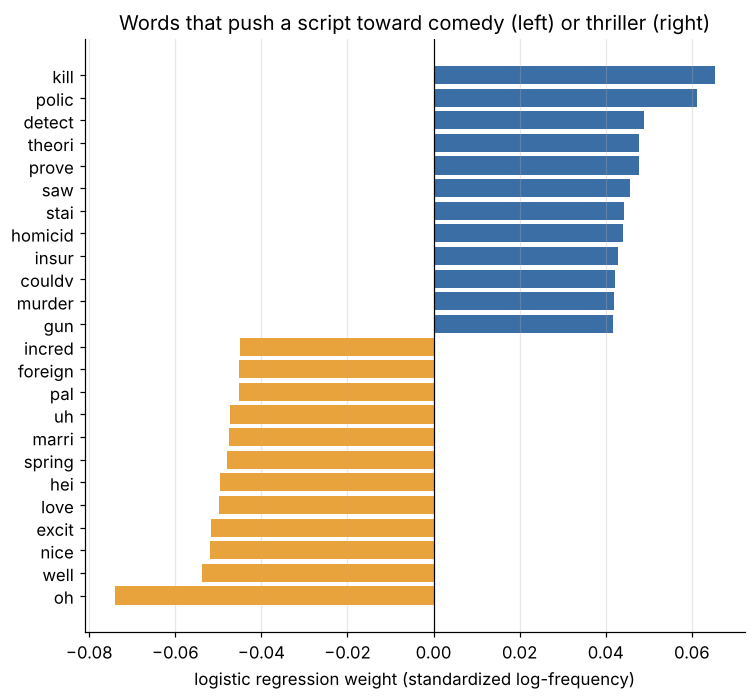

In [10]:
tuned_logreg.fit(X, y)
final_model = tuned_logreg.best_estimator_
final_params = tuned_logreg.best_params_
print("Chosen settings:", final_params)
kept_words = X.columns[final_model[0].keep_]
print(f"Words kept: {len(kept_words):,} of {X.shape[1]:,}")
coefs = pd.Series(final_model[-1].coef_[0], index=kept_words).sort_values()
top = pd.concat([coefs.head(12), coefs.tail(12)])

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(top.index, top.values, color=[COMEDY if v < 0 else THRILLER for v in top.values])
ax.axvline(0, color="black", lw=0.8); ax.grid(axis="y", visible=False)
ax.set(xlabel="logistic regression weight (standardized log-frequency)",
       title="Words that push a script toward comedy (left) or thriller (right)")
plt.tight_layout(); plt.savefig("figures/top_words.png", bbox_inches="tight"); plt.show()

With rare words gone, the weights read like genre vocabulary instead of a cast list. Thrillers lean on crime and investigation words. Comedies lean on **how people talk**: interjections, filler and casual reactions. That conversational signal is something nobody would think to hand-pick, and it's a big reason the model beats the 10-word list.

## 7. Where does it go wrong?

Out-of-fold predictions (every movie is predicted by a model that never saw it) show which kinds of mistakes it makes:

Comedies caught:  96/119 (81%)
Thrillers caught: 196/214 (92%)


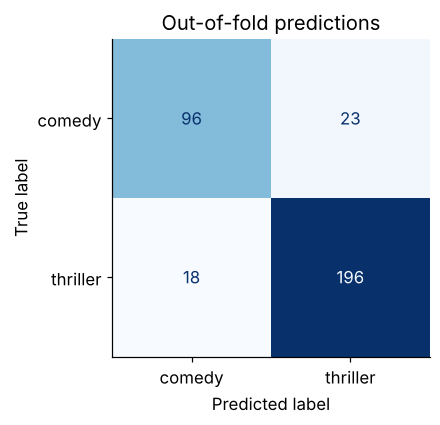

In [11]:
oof_proba = cross_val_predict(tuned_logreg, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                              method="predict_proba")[:, 1]
oof_pred = (oof_proba >= 0.5).astype(int)

fig, ax = plt.subplots(figsize=(4.4, 4))
ConfusionMatrixDisplay(confusion_matrix(y, oof_pred), display_labels=["comedy", "thriller"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.grid(False); ax.set_title("Out-of-fold predictions")
plt.tight_layout(); plt.savefig("figures/confusion_matrix.png", bbox_inches="tight"); plt.show()

cm = confusion_matrix(y, oof_pred)
print(f"Comedies caught:  {cm[0,0]}/{cm[0].sum()} ({cm[0,0]/cm[0].sum():.0%})")
print(f"Thrillers caught: {cm[1,1]}/{cm[1].sum()} ({cm[1,1]/cm[1].sum():.0%})")

In [12]:
errors = movies.assign(p_thriller=oof_proba.round(2), predicted=np.where(oof_pred, "thriller", "comedy"))
errors = errors[errors["predicted"] != errors["Genre"]]
errors["confidence"] = (errors["p_thriller"] - 0.5).abs()
errors.sort_values("confidence", ascending=False)[["Title", "Year", "Genre", "predicted", "p_thriller"]].head(12)

,Title,Year,Genre,predicted,p_thriller
97,star trek iv: the voyage home,1986,comedy,thriller,1.00
119,dr. strangelove or: how i learned to stop worrying and love the bomb,1964,comedy,thriller,1.00
215,the sting,1973,comedy,thriller,1.00
240,slither,2006,comedy,thriller,0.93
212,batman forever,1995,thriller,comedy,0.07
31,crime spree,2003,comedy,thriller,0.91
295,the adventures of buckaroo banzai across the 8th dimension,1984,comedy,thriller,0.90
53,innerspace,1987,comedy,thriller,0.88
45,hellraiser: hellseeker,2002,thriller,comedy,0.16
174,the shining,1980,thriller,comedy,0.18


Reading the misses is the most useful part. The most confident mistakes are **comedies set in thriller territory**: a con-artist caper (*The Sting*), a nuclear-war satire (*Dr. Strangelove*), sci-fi adventures (*Star Trek IV*, *Innerspace*, *Buckaroo Banzai*), a crime spree and a horror-comedy (*Slither*). Their scripts are full of crime, danger and investigation words, just played for laughs. Going the other way, campy or character-driven thrillers (*Batman Forever*, *Heavenly Creatures*) talk more like comedies. Word counts can't see **tone**, which is the main thing separating a comedy about a heist from a thriller about one.

## 8. Same 50-movie test set as the original course project

For a direct comparison with the original assignment, the last 15% of the file (50 movies) is the test set, with nothing tuned on it:

In [13]:
n_train = int(len(movies) * 17 / 20)
Xtr, Xte, ytr, yte = X.iloc[:n_train], X.iloc[n_train:], y.iloc[:n_train], y.iloc[n_train:]

holdout = {
    f"k-NN, 10 hand-picked words (k={best_k})":
        KNeighborsClassifier(best_k).fit(Xtr[hand_picked], ytr).score(Xte[hand_picked], yte),
    "Logistic regression, log-scaled + rare words dropped (tuned)": tuned_logreg.fit(Xtr, ytr).score(Xte, yte),
}
pd.Series(holdout, name="accuracy on the 50 held-out movies").round(3).to_frame()

,accuracy on the 50 held-out movies
"k-NN, 10 hand-picked words (k=23)",0.78
"Logistic regression, log-scaled + rare words dropped (tuned)",0.82


With only 50 test movies, each one is worth 2 percentage points, so the cross-validated numbers above are the more reliable estimate.

## 9. Takeaways

- **Vocabulary alone tells comedies from thrillers about 88% of the time** (cross-validated), well above the 64% from always guessing "thriller" and the ~80% from k-NN on hand-picked words.
- **More features made k-NN worse.** It needs a small, relevant vocabulary. Picking words by chi-squared inside each fold matched or beat hand-picking.
- **A linear model with the right preprocessing won.** Log-scaling the skewed frequencies, regularizing the weights and dropping words used in under 10% of scripts let logistic regression use ~1,850 words without memorizing character names. It also beat Naive Bayes, the classic text baseline.
- **Inspecting the model improved it.** The jump from 85% to 88% came from reading the learned weights, spotting character names, and fixing the cause.
- **The remaining errors are mostly genre-blends**, where tone matters more than vocabulary.

**Next steps:** sentence-embedding features (which capture meaning, not just word counts), more genres than two, and TF-IDF features to downweight words common to every script.